# DEL 1 STATISTISK ANALYS AV HÄLSODATA

## Introduktion och syfte

Syftet med analysen är att bestiva ett hälsodataset och undreköka påstånde att rökare har högre genomsnittligt blodryck än icke-rökare.  

Analysen omfattar beskrivande statistik, diagram, simulering av sjukdomförekomst, 95% konfidensintervall (normalapproximation och boostrap), ett ensidigt Welchs t-test och en simulering av statistisk power. 

Data kommer från datasatet health_study_dataset.csv. Simulerade data advänds för att illustrera hur statistiska metoder funkar, inte som oberoende bevis för samband i population.

### 1.1. Import av bibliotek

In [1]:
%cd ..

c:\Users\kataz\Desktop\skola\health_analysis


In [2]:
import os
print(os.getcwd())

c:\Users\kataz\Desktop\skola\health_analysis


In [3]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from src.analyzer import HealthAnalyzer

### 1.2. Datainläsning

In [4]:

df = pd.read_csv("data/health_study_dataset.csv")
analyzer = HealthAnalyzer(df)

age_stats = analyzer.summary("age")
age_stats

{'count': 800,
 'mean': np.float64(49.42625),
 'median': np.float64(50.0),
 'max': np.int64(90),
 'min': np.int64(18),
 'std': np.float64(14.501117679508145),
 'se': np.float64(0.5126919322982171)}

### 1.3. Grundläggande beräkningar för blodtryck

Här beräknas medelvärde, standardavvikels och standartfel för systoliska blotrycket. Saknades värden tas bort före beräkningena.

In [5]:
bp_stats = analyzer.summary("systolic_bp")

bp_values = df["systolic_bp"].dropna()
bp_count = bp_stats["count"]
bp_mean = bp_stats["mean"]
bp_std = bp_stats["median"]
bp_se = bp_stats["std"]
bp_median = bp_stats["se"]


### 1.4. Konstanter

Konstanterna samlas här för att göra analysen tydlig och reproducerbar.  
`RANDOM_SEED` används för att simuleringarna ska kunna upprepas.  
 Signifikansnivån sätts i förväg till `ALPHA = 0.05`.  
 Antalet power-simuleringar är 10 000 per scenario, vilket minskar slumpvariation i den simulerade andelen signifikanta test.

In [6]:
from src.config import (
    RANDOM_SEED,
    ALPHA,
    BP_COLUMN,
    SEX_COLUMN,
    SMOKER_COLUMN,
    SIM_GROUP_SIZE,
    N_BOOTSTRAP,
    BOOTSTRAP_START,
    BOOTSTRAP_STEP,
    N_POWER_SIM,
    POWER_SAMPLE_SIZE,
    )

### 1.5. Färgpalett och figurstil för visualisering



In [7]:
from src.styles import COLORS, SMOKING_COLORS, SEX_COLORS
print(SEX_COLORS)

{'F': '#96C996', 'M': '#578A57'}


### 1.6. Inställningar för diagrammers utseende

Funktion `style_axis` används för ge diagrammen en enhetlig stil.

In [8]:
from src.styles import setup_plot_style, style_axis

setup_plot_style()

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [9]:
print("Databeset: de första och sista tre råderna")
display(df.head(3).style.hide(axis="index"))
display(df.tail(3).style.hide(axis="index"))

print(f"\nDatasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")
print(f"\n{"Kolumnamn":<20} Datatype:")
for column in df.columns:
    print(f" - {column:<15} : {df[column].dtype}")

Databeset: de första och sista tre råderna


id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
1,57,F,168.900000,65.800000,141.800000,4.580000,No,0
2,47,M,180.400000,95.900000,144.800000,5.180000,Yes,0
3,59,F,169.900000,82.200000,151.700000,6.160000,No,0


id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
798,60,F,175.000000,49.700000,146.500000,5.570000,No,0
799,50,F,172.600000,55.300000,155.000000,3.580000,No,0
800,50,M,189.200000,79.400000,139.700000,5.620000,No,0



Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering och datarensning

Här kontrolleras Id_värdena är unika och kolumnerna för kön, rökstatus och sjukdom innehäller förväntade värde.

"Korrekt" betyder att endast en kontrollerade regeln har uppfyllts, inte att alla datavärden är felfria.

In [10]:
expected_values = ({"id": df["id"].is_unique,
                    "sex": df["sex"].isin(SEX_COLUMN).all(),
                    "smoker": df["smoker"].isin(SMOKER_COLUMN).all(),
                    "disease": df["disease"].isin([0, 1]).all(),
                    })
display(pd.DataFrame(expected_values, index=["Validering"]).replace({True: "Korrekt", False: "Fel"}))

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

Tabellen visar antalet saknade värden i varje kolumn.

In [11]:

display(df.isna().sum().to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


Det finns inga saknade värden i databasen.

### 2.2.2. Validering av datatyper

Här kontrolleras datatyper för värderna i varje kolumn innehäller med förväntade datatyper.

"Korrekt" betyder att endast en kontrollerade regeln har uppfyllts, men bekräftar inte i sig att alla numeriska värde är rimliga.

In [12]:
expected_types = {
    "id": "int", 
    "age": "int", 
    "sex": "str", 
    "height": "float",
    "weight": "float",
    "systolic_bp": "float",
    "cholesterol": "float",
    "smoker": "str",
    "disease": "int"
    }


correct_columns = []
incorrect_columns = []


for column in df.columns:
    expected_type = expected_types[column]
    passed = True
    
    for value in df[column]:
        actual_type = type(value).__name__
        if actual_type != expected_type:
            passed = False
    if passed:
        correct_columns.append(column)
    else:
        incorrect_columns.append(column)

result = {column: "Korrekt" if column in correct_columns else "Fel" for column in df.columns}

display(pd.DataFrame(result, index=["Datatyp validering"]))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


Inga saknade värden eller avvikelser från de kontrollerade datatyperna och kategorierna upptäcktes.  
Kontroll av medicinskt rimliga gränsvärden eller mätfel ingår däremot inte här.

## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [13]:
calculate_columns = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(
    ["mean", "median", "min", "max"])

calculate_columns = calculate_columns.rename(index={
    "mean": "Medelvärde", "median":"Median", "min": "Minimun", "max": "Maximum"})

display(calculate_columns.round(2))

,age,height,weight,systolic_bp,cholesterol
Medelvärde,49.43,171.85,73.41,149.18,4.93
Median,50.00,171.35,73.20,149.40,4.97
Minimun,18.00,144.40,33.70,106.80,2.50
Maximum,90.00,200.40,114.40,185.90,7.88


Medelvärdet och medianen ligger nära varandra för alla fem variabler, vilket kan tyda på att fördelningarna är ungefär symmetriska. Detta är dock ingen bevis på symmetri.

### 3.2. Visualisering

Olika diagram visar hur hälsodata är fördelade.

#### 3.2.1 Fördelning av systoliskt blodtryck

Histogramme visar fördelningen av systolisk blodtryck för 800 personar

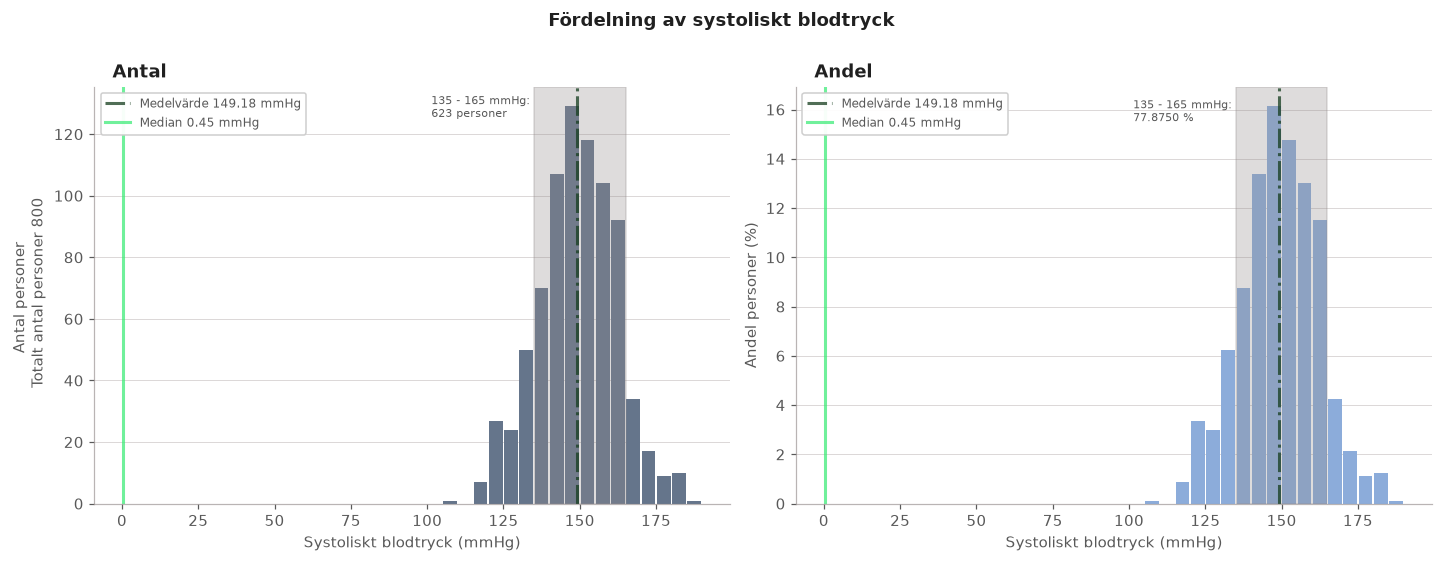

In [14]:

bp_bin_width = 5
bp_bins = np.arange(
    np.floor(bp_values.min() / bp_bin_width) * bp_bin_width,
    np.ceil(bp_values.max() / bp_bin_width) * bp_bin_width + bp_bin_width,
    bp_bin_width,
)

bp_hist_counts, _ = np.histogram(bp_values, bins=bp_bins)
bp_hist_percent = bp_hist_counts / bp_count * 100
bp_bin_centers = (bp_bins[:-1] + bp_bins[1:]) / 2

bp_selected = bp_values.between(135, 165)
bp_selected_count = bp_selected.sum()
bp_selected_perdent = bp_selected.mean() * 100


fig_bp, axes_bp = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for axis, values, color, subtitle, ylabel in [
    (axes_bp[0], bp_hist_counts, COLORS["blood_pressure"], "   Antal", f"Antal personer \n Totalt antal personer {bp_count}"),
    (axes_bp[1], bp_hist_percent, COLORS["blood_pressure_light"], "   Andel", "Andel personer (%)"),
]:
    axis.bar(bp_bin_centers, values, width=bp_bin_width * 0.90, color=color)
    axis.axvspan(135, 165, color="#928B8B", alpha=0.3)
    axis.axvline(bp_mean, color=COLORS["reference"], linestyle="-.",
                  alpha=0.75, linewidth=2, label=f"Medelvärde {bp_mean:.2f} mmHg")
    axis.axvline(bp_median, color=COLORS["reference_m"], linestyle="-",
                  alpha=0.7, linewidth=2, label=f"Median {bp_median:.2f} mmHg")
    axis.set_title(subtitle, loc="left")
    axis.set(xlabel="Systoliskt blodtryck (mmHg)", ylabel=ylabel)
    axis.legend(loc="upper left")
    style_axis(axis)

axes_bp[0].text(0.53, 0.98, f"135 - 165 mmHg: \n{bp_selected_count} personer ",
                 transform=axes_bp[0].transAxes, va="top", color=COLORS["muted"], fontsize=7)
axes_bp[1].text(0.53, 0.97, f"135 - 165 mmHg: \n{bp_selected_perdent:.4f} %",
                 transform=axes_bp[1].transAxes, va="top", color=COLORS["muted"], fontsize=7)
fig_bp.suptitle("Fördelning av systoliskt blodtryck\n", fontweight="bold")
plt.show()


Av 800 personer har 623 (77,88 %) systoliskt blodtryck mellan 135 och 165 mmHg. Medelvärdet är cirka 149,18 mmHg och ligger nära medianen 149,40 mmHg. Histogrammet ser ungefär symmetriskt ut, men likheten mellan medelvärde och median bevisar inte symmetri.  
  
Intervallet 135–165 mmHg används här **endast** för att beskriva fördelningen.


#### 3.2.2 Viktfördelning efter kön

Lådagram jämför viktfödelningen mellan kvinnor och män.  
Diagrammet visar medianen, kvartilerna och spridningen av vikten och avvikande värde.

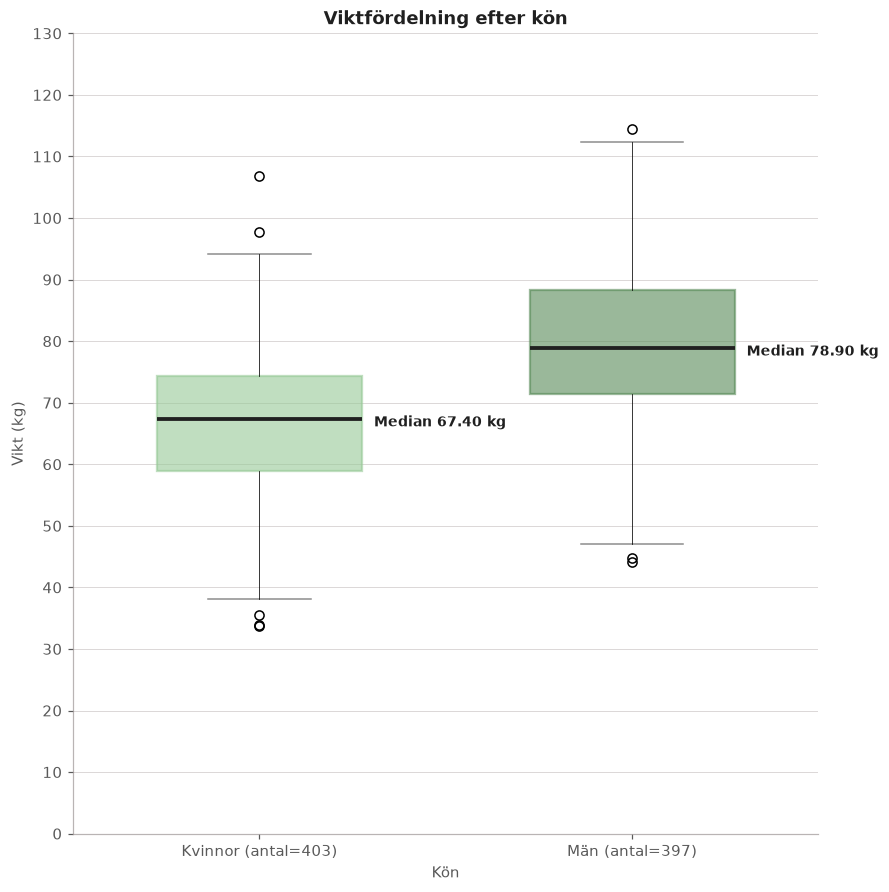

In [15]:
median_weight_by_sex = df.groupby("sex")["weight"].median()
weight_groups = [df.loc[df["sex"] == sex, "weight"].dropna() for sex in SEX_COLUMN]
weight_labels = [f"{label} (antal={len(values)})" for label, values in zip(["Kvinnor", "Män"], weight_groups)]

fig_weight, ax_weight = plt.subplots(figsize=(8, 8), layout="constrained")
weight_box = ax_weight.boxplot(
    weight_groups, patch_artist=True, tick_labels=weight_labels, widths=0.55,
    medianprops={"color": COLORS["ink"], "linewidth":2.5},
    whiskerprops={"linewidth":0.5},
    capprops={"marker": None, "markersize":7, "alpha":0.45, "markeredgecolor": COLORS["muted"]},
)

for patch, sex in zip(weight_box["boxes"], SEX_COLUMN):
    patch.set(facecolor=SEX_COLORS[sex], alpha=0.6, edgecolor=SEX_COLORS[sex], linewidth=1.5)

for pos, sex in enumerate(SEX_COLUMN, start=1):
    median = median_weight_by_sex.loc[sex]
    ax_weight.annotate(f"Median {median:.2f} kg", (pos, median),
                       xytext=(75, -5), textcoords="offset points", fontsize=9,
                       color=COLORS["ink"], fontweight="bold")
    
ax_weight.set(title="Viktfördelning efter kön", xlabel="Kön", ylabel="Vikt (kg)")
style_axis(ax_weight)

ax_weight.set_yticks(range(0, 131, 10))

plt.show()


Män i datasetet har en högre medianvikt än kvinnor. Skillnaden mellan medianerna är 11,50kg.  
Båda grupperna har några avvikande värden.

#### 3.2.3. Rökvanor i hela databaset

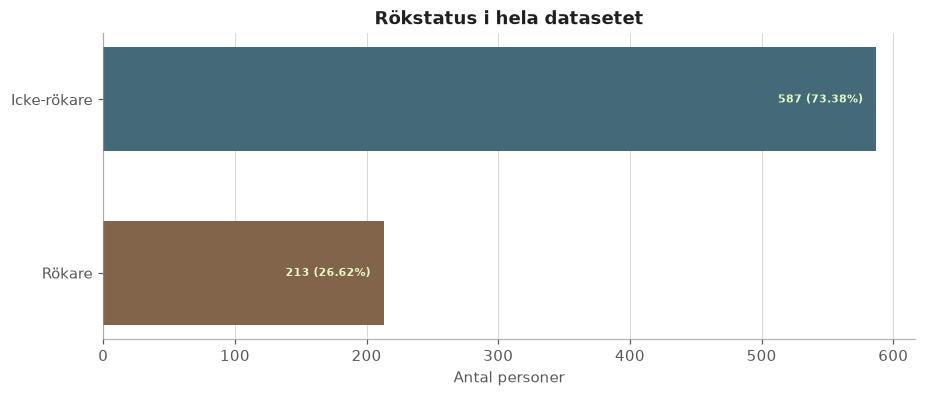

In [16]:
smoking_counts = pd.crosstab(df["sex"], df["smoker"]).reindex(
    index=SEX_COLUMN, columns=SMOKER_COLUMN, fill_value=0
)
smoking_perc = smoking_counts.div(smoking_counts.sum(axis=1), axis=0) * 100
smoking_all_counts = smoking_counts.sum(axis=0)

fig_smoking, ax_smoking = plt.subplots(figsize=(8.3, 3.5), layout="constrained")
smoking_labels = {"No": "Icke-rökare", "Yes": "Rökare"}

for idx, status in enumerate(SMOKER_COLUMN):
    count = int(smoking_all_counts.loc[status])
    ax_smoking.barh(idx, count, color=SMOKING_COLORS[status], height=0.6)
    ax_smoking.text(count - 10, idx,
                    f"{count} ({count / smoking_all_counts.sum():.2%})",
                    ha="right", va="center", fontweight="bold", color=COLORS["text"], fontsize =7)
ax_smoking.set_yticks(range(len(SMOKER_COLUMN)),[smoking_labels[status] for status in SMOKER_COLUMN])
ax_smoking.invert_yaxis()
ax_smoking.set(title="Rökstatus i hela datasetet", xlabel="Antal personer")
style_axis(ax_smoking, grid_axis="x")
plt.show()

Av totalt 800 personer är 587(73,38%) icke-rökare och 213(26,62%) rökare. Rökare utgör minoritet i databaset.

#### 3.2.4. Rökstatus efter kön

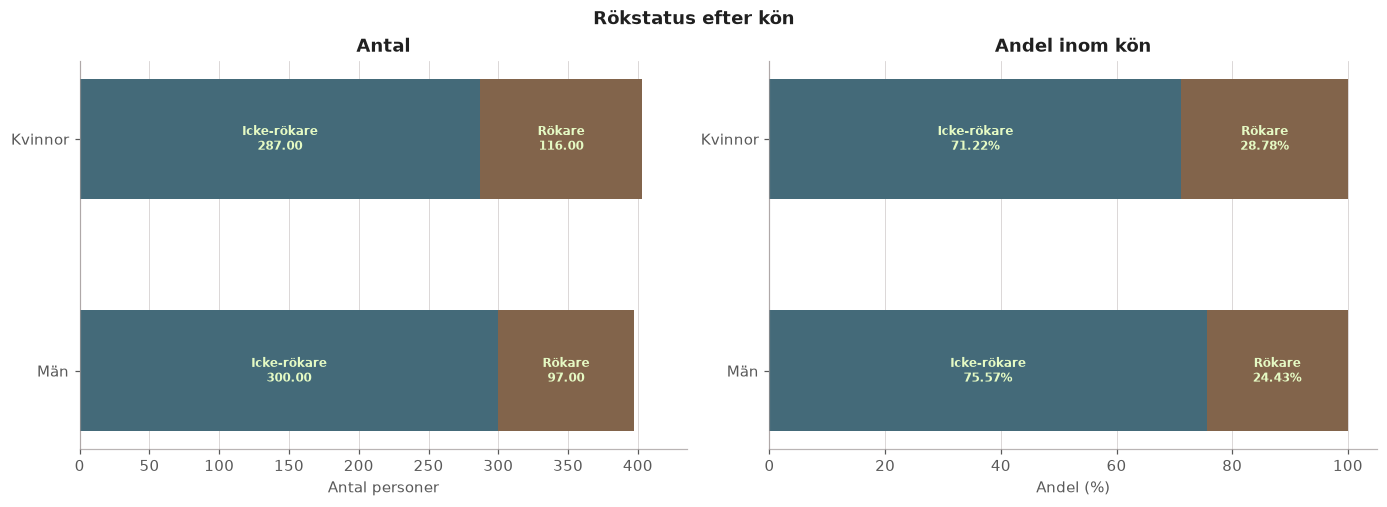

In [17]:
fig_smoking_sex, axes_smoking_sex = plt.subplots(
    1, 2, figsize=(12.5, 4.5), layout="constrained"
)
sex_names = ["Kvinnor", "Män"]
sex_positions = np.arange(len(SEX_COLUMN))
for axis, table, subtitle, xlabel, is_percent in [
    (axes_smoking_sex[0], smoking_counts, "Antal", "Antal personer", False),
    (axes_smoking_sex[1], smoking_perc, "Andel inom kön", "Andel (%)", True),
]:
    left = np.zeros(len(SEX_COLUMN))
    for status in SMOKER_COLUMN:
        widths = table[status].to_numpy()
        bars = axis.barh(sex_positions, widths, left=left, height=0.52,
                         label=smoking_labels[status], color=SMOKING_COLORS[status])
        for bar, value in zip(bars, widths):
            axis.text(bar.get_x() + bar.get_width() / 2,
                          bar.get_y() + bar.get_height() / 2,
                          (f"{smoking_labels[status]}\n{value:.2f}%" if is_percent
                           else f"{smoking_labels[status]}\n{value:.2f}"),
                          ha="center", va="center", color=COLORS["text"], fontweight="bold", fontsize=8)
        left += widths
    axis.set_yticks(sex_positions, sex_names)
    axis.invert_yaxis()
    axis.set(title=subtitle, xlabel=xlabel)
    axis.set_xlim(0, 105 if is_percent else float(table.sum(axis=1).max()) * 1.08)
    style_axis(axis, grid_axis="x")

fig_smoking_sex.suptitle("Rökstatus efter kön", fontweight="bold")
plt.show()

Andelen rökare och icke-rökare är relativt lika bland kvinnor och män. Åndelen rökare i datasetet är något högre bland kvinnor(28,78%) än bland män(24,43%).  
Diagrammet visar mönster, doch bevisar inte orsakssamband mellan kön och rökstatus.

## 4. Simulering kopplad till caset

### 4.1 Andelen personer i datasetet som har sjukdom

 I analysen antar vi att:
 disease = 0 betyder att personen har inte sjukdom och att disease = 1 betyder att personen har sjukdomen.

In [18]:
disease_rate = df["disease"].mean()

print(f"Andel personer med sjukdom:  {disease_rate:.4%}")

Andel personer med sjukdom:  5.8750%


### 4.2 Ny grupp med 1 000 slumpade personer 

Ny grupp har 1000 simulerade personer med samma sannolikhet för sjukdom som i det ursprungliga databaset(5,875%) och däeför har ingen oberoende kontroll av sjukdomsförekomsten i population.  
Att resultatet ska bli reproducerbar används fast seed.

In [19]:
rng_disease = np.random.default_rng(RANDOM_SEED)
simulated_objects = rng_disease.binomial(1, disease_rate, size=SIM_GROUP_SIZE)
simulated_yes_group = simulated_objects.mean()

print(f"Simulerad andel med sjukdom: {simulated_yes_group:.2%}")

Simulerad andel med sjukdom: 5.40%


I ny grupp är 54 personer med sjukdom.

### 4.3. Jämförelse

In [20]:
print(f" Andel personer med sjukdom i datasetet:  {disease_rate:.4%}")
print(f" Simulerad andel med sjukdom:             {simulated_yes_group:.4%}")
print(f" Skillnad:                               {simulated_yes_group - disease_rate:.4%}")

 Andel personer med sjukdom i datasetet:  5.8750%
 Simulerad andel med sjukdom:             5.4000%
 Skillnad:                               -0.4750%


Andelen personer med sjukdom är 5,875% i det utsprungliga datasetet och 5,400% i den simmulerade gruppen. Skillnaden är resultat av slumpmässig variation i simuleringen.

## 5. Konfidensintervall - normalapproximation

### 5.1. Värdena

Värdena beräknades i avsnitt 1.

In [21]:
results = pd.DataFrame({
    "Statistik": ["Medelvärde:",
                   "Standardavvikelse:",
                   "Antal observationer:",
                   "Standardfel:"
                       ],
    "Värde": [
        f"{bp_mean:.4f} mmHg",
        f"{bp_std:.4f} mmHg",
        str(bp_count),
        f"{bp_se:.4f} mmHg"
                       ]
})

display(results.style.hide(axis="index"))

Statistik,Värde
Medelvärde:,149.1786 mmHg
Standardavvikelse:,149.4000 mmHg
Antal observationer:,800
Standardfel:,12.7934 mmHg


### 5.2 Konfidensintervall - felmarginal, gränser

Ett 95 % konfidensintervall adväns att ge rimlig balans mellan precisin och säkerhet. Det betyder att om nytt intervall räknas för samma undersökning om och om, skulle ungefär 95% av intervallen innehålla det verkliga medelvärde för hela population. Verkliga medelvärde för hela population vet vi inte. Räkning utgåt från att datasetet är representativt för population.  

SE är standartfel  
s är standartavvikelse  
n är antal observation(datasetet har 800)  
$ \bar{x} $ är medelvärde(i datasetet är 149,18 mmHg )

$
KI_{95\%} = \bar{x} \pm 1,96 \cdot SE  
$  
$
SE = \frac{s}{\sqrt{n}}
$

In [22]:
normal_margin = stats.norm.ppf(1 - ALPHA / 2) * bp_se
normal_ci = (bp_mean -normal_margin, bp_mean + normal_margin) 
print(f"Felmarginal: {normal_margin:.4f} mmHg")
print(f"normalapproximations gränser: {normal_ci[0]:.4f} mmHg och {normal_ci[1]:.4f} mmHg")

Felmarginal: 25.0745 mmHg
normalapproximations gränser: 124.1041 mmHg och 174.2532 mmHg


Resultatet visar, doch inte garanterar att det genomsnittliga blodtrycket i hela population uppskattes ungefär mellan 148,2921 och 150,0651 mmHg, baserad på data i datsetet.  
Felmarginal visar hur osäkert vårt medetvärde är som uppskattning av hela populations medevärde. I vårt fall går 0,8865 mmHg (felmarginal) under och över medelvärdet(149,18 mmHg).

## 6. Konfidensintervall - bootstrap

I den här delen görs många slupmässiga urval från ursprungliga dataset. Varje urval innehåller 800 värden, samma värde kan väljas flera gånger.  
Ett fast seed advänds för att resultat ska uppraperas.  
Medelvärde räknas ut för varje urval och resultat är att konfidensintervall kan uppskattas.

Bootstrap kräver inte exakt normelfördelade blodtryckvärdena, Storleken på observation är tillräklig stor, men resultat beror på representativ urval och metods begränsningar.

In [23]:
rng_bootstrap =np.random.default_rng(RANDOM_SEED)
bp_array = bp_values.to_numpy()
bootstrap_means= np.empty(N_BOOTSTRAP, dtype=float)
bootstrap_batch_size = 2000
for batch_start in range(0, N_BOOTSTRAP, bootstrap_batch_size):
    batch_end = min(batch_start + bootstrap_batch_size, N_BOOTSTRAP)
    samples = rng_bootstrap.choice(bp_array, size=(batch_end - batch_start, bp_count), replace=True)
    bootstrap_means[batch_start:batch_end] = samples.mean(axis=1)


### 6.1 Bootstrapintervallets gränser

In [24]:
bootstrap_ci = tuple(np.percentile(bootstrap_means, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]))
print(f"95% CI, bootstrap: [{bootstrap_ci[0]:.4f}, {bootstrap_ci[1]:.4f}] mmHg")

95% CI, bootstrap: [148.2905, 150.0691] mmHg


Resultatet visar, men inte garanterar att det genomsnittliga blodtrycket i hela population uppskattes ligger ungefär mellan 148,2905 och 150,0691 mmHg, baserad på data i datsetet.  


### 6.2 Stability när antalet bootstrapreplikat ökar

Här undersöks hur konfidensintervallet förändras när antalet bootstrapupprepningar ökar.  
Regler: båda gränser jämföras och simuleging avslutas om förändringen är högst 0,01 mmHg vid 10 kontroller i rad.

In [25]:

bootstrap_check_sizes = list(range(BOOTSTRAP_START, N_BOOTSTRAP, BOOTSTRAP_STEP))
if not bootstrap_check_sizes or bootstrap_check_sizes[-1] != N_BOOTSTRAP:
    bootstrap_check_sizes.append(N_BOOTSTRAP)
bootstrap_lower_bounds = []
bootstrap_upper_bounds = []
bootstrap_ci_changes = []
previous_ci = None
for n_replicates in bootstrap_check_sizes:
    current_ci = tuple(np.percentile(bootstrap_means[:n_replicates],
                                    [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]))
    bootstrap_lower_bounds.append(current_ci[0])
    bootstrap_upper_bounds.append(current_ci[1])
    if previous_ci is not None:
        bootstrap_ci_changes.append(max(abs(current_ci[0] - previous_ci[0]),
                                        abs(current_ci[1] - previous_ci[1])))
    previous_ci = current_ci

tolerance = 0.01
checks_needed = 10
stop_at = None

for i in range(checks_needed, len(bootstrap_ci_changes) + 1):
    recent_changes = bootstrap_ci_changes[i - checks_needed:i]

    if all(change <= tolerance for change in recent_changes):
        stop_at = bootstrap_check_sizes[i]
        break

if stop_at is not None:
    print(f"Föreslaget stopp: {stop_at} bootstrapreplikat")
else:
    print("stoppvillkoret uppnåddes inte.")

Föreslaget stopp: 25500 bootstrapreplikat


### 6.3. Diagram

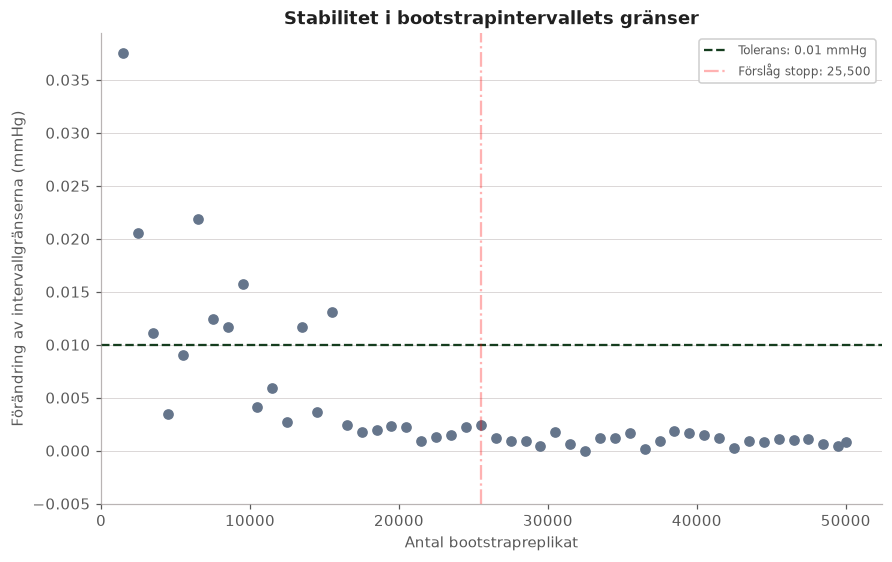

In [26]:
fig_bootstrap_stability, ax_bootstrap_stability = plt.subplots(
    figsize=(8, 5),
    layout="constrained"
)

ax_bootstrap_stability.scatter(
    bootstrap_check_sizes[1:],
    bootstrap_ci_changes,
    color=COLORS["blood_pressure"]
)

ax_bootstrap_stability.axhline(
    0.01,
    color=COLORS["reference"],
    linestyle="--",
    label="Tolerans: 0.01 mmHg"
)

ax_bootstrap_stability.set(
    title="Stabilitet i bootstrapintervallets gränser",
    xlabel="Antal bootstrapreplikat",
    ylabel="Förändring av intervallgränserna (mmHg)"
)

if stop_at is not None:
    ax_bootstrap_stability.axvline(
        x=stop_at,
        color="red",
        linestyle="-.",
        linewidth=1.5,
        alpha=0.3,
        label=(f"Förslåg stopp: {stop_at:,}")
    )
ax_bootstrap_stability.legend()
ax_bootstrap_stability.set_ylim(bottom=-0.005)
ax_bootstrap_stability.set_xlim(left=0)

style_axis(ax_bootstrap_stability)

plt.show()

Ändringarna i intervallgränserne bli nästan lika eller mindre när antalet replikation ökar. Met detta diagnostiska kriterium föreslår stoppa efter 25500 upprepningar.  
I diagram visas alla 50000 upprepningar och utvecklig bli efter rekomenderat stopp punkt.

### 6.4. Jämförelse mellan metoderna

In [27]:
ci_table = pd.DataFrame({
    "Metod": ["Normalapproximation", "Bootstrap"],
    "Nedre gräns (mmHG)": [normal_ci[0], bootstrap_ci[0]],
    "Över gräns (mmHg)":  [normal_ci[1], bootstrap_ci[1]]
})

display(ci_table.round(4).style.hide(axis="index"))

Metod,Nedre gräns (mmHG),Över gräns (mmHg)
Normalapproximation,124.104100,174.253200
Bootstrap,148.290500,150.069100


Båda metoderna ger nästan samma 95-procentiga konfidensintervall. Det är rimligt med ett relativt stort stickprov och en ungefär symmetrisk fördelning av blodtrycket. 

Normalapproximationen använder standardfelet och normalfördelningens kritiska värde, medan bootstrap använder percentiler från upprepade stickprov med återläggning.

Metoderna bygger dock på **samma dataset**. Att deras resultat liknar varandra är därför ingen oberoende bekräftelse på populationsmedelvärdet.  

## 7. Hypotesprövning

### Påstående :" Rökare har högre genomsnittligt systolisk blodtryck än icke-rökare."

### 7.1 Formulera hypoteser


H0: Rökare har inte högre medelblodtryck än icke-rökare.  
H1: Rökare har högre medelblodtryck än icke-rökare.  
  
Ett ensidigt t-test eftersom analysen vill undersöka om rökare har högre genomsnittligt systolisk blodtryck än icke-rökare, inte endast om grupperna skiljer sig åt. Riktningen anges i uppgiften.

Welchs t-test passar här därför att grupperna har olika antal personer, men just det är inte ensamt skäl att välja Welch. Andra skäl är att blotrycket behövs inte ha samma varians i båda grupperna, som krävs för students t-test.

### 7.2. Statistisk test - Welchs t-test
  
Signifikansnivå : Den acceptable risk att förkasta nollhypotesen trots att den är sannt(typ I-fel) valdes på höst 5 % . 

### 7.3 Data

In [28]:
smoker_bp = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()
no_smoker_bp = df[df["smoker"] == "No"]["systolic_bp"].dropna()

smoker_n, non_smoker_n = len(smoker_bp), len(no_smoker_bp)
smoker_mean, non_smoker_mean = smoker_bp.mean(), no_smoker_bp.mean()
smoker_std, non_smoker_std = smoker_bp.std(ddof=1), no_smoker_bp.std(ddof=1)
smoker_fraction = smoker_n / (smoker_n + non_smoker_n)

smoker_no_smoker_summary = pd.DataFrame({
    "Grupp": ["Rökare", "Icke-rökare"],
    "Antal": [smoker_n, non_smoker_n],
    "Medelblodtryck (mmHg)": [smoker_mean, non_smoker_mean],
    "Standardavvikelse": [smoker_std, non_smoker_std]
})

display(smoker_no_smoker_summary.round(4).style.hide(axis="index"))

Grupp,Antal,Medelblodtryck (mmHg),Standardavvikelse
Rökare,213,149.524900,13.267800
Icke-rökare,587,149.053000,12.626000


Det finn 213 rökare och 587 icke-rökare i datasetet. Skillnaden i genomsnittligt systolisk blodtryck  mellan rökare och icke-rökare är 0,47 mmHg. Rökare i daset har något högre medevärde, men det betyder inte att skillnaden bekräftar att rökning påverkat systolisk blodtryk.

### 7.4. Welch-testet


In [29]:
welch_ttest = stats.ttest_ind(smoker_bp, no_smoker_bp, equal_var=False, alternative="greater")
print(f"Welch t-statistik: {welch_ttest.statistic:.4f}")
print(f"Welch p-värde:     {welch_ttest.pvalue:.4f}")
print("\nReslutat: H0" , "förkastas." if welch_ttest.pvalue  < ALPHA  else "förkastas inte." )

Welch t-statistik: 0.4503
Welch p-värde:     0.3264

Reslutat: H0 förkastas inte.


Welchs ensidiga t-test ger p ≈ 0,3264, vilket är större än α = 0,05. **Nollhypotesen förkastas därför inte.**   
Analysen ger inte tillräckligt statistiskt stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.  


## 8. Power-analys genom simulering

Statistisk styrka (*power*) visar hur stor sannolikheten är att teste upptäcker en verklig skillnad mellan två grupper.
Här upprepas ett ensidigt Welch-test 10 000 gånger för varje urvalsstorlek. Andelen test med p < 0,05 ger en uppskattning av power.

**Viktig begränsning:** Den första simuleringen använder den **observerade** skillnaden på cirka 0,47 mmHg och de uppskattade standardavvikelserna. dessa värden antas vara sanna i modellen, men vi har ingen bevis om de motsvarar population. 

Urvalsstorlekarna 100–3 200 valdes för att visa utvecklingen under och över datasetets storlek (800 personer); 10 000 simuleringar ger en relativt stabil modellbaserad andel. Gruppandelen 213/800(rökare/alla) hålls konstant i denna första jämförelse.

In [30]:
rng_power = np.random.default_rng(RANDOM_SEED)
power_rows = []
power_batch_size = 250

for total_n in POWER_SAMPLE_SIZE:
    simulated_smoker_n = round(total_n * smoker_fraction)
    simulated_non_smoker_n = total_n - simulated_smoker_n
    welch_significant = 0

    for batch_start in range(0, N_POWER_SIM, power_batch_size):
        batch_n = min(power_batch_size, N_POWER_SIM - batch_start)
        sim_smoker_power =rng_power.normal(
            smoker_mean, smoker_std, size=(batch_n, simulated_smoker_n)
        )
        sim_no_smoker_power =rng_power.normal(
            non_smoker_mean, non_smoker_std, size=(batch_n, simulated_non_smoker_n)
        )
        wech_p = stats.ttest_ind(
            sim_smoker_power, sim_no_smoker_power, axis=1, equal_var=False, alternative="greater"
        ).pvalue
        welch_significant += np.count_nonzero(wech_p < ALPHA)

    power_rows.append({
        "Total antal:": total_n,
        "Simulation - antal rökare:": simulated_smoker_n,
        "Simulation - antal icke-rökare:": simulated_non_smoker_n,
        "Welch power:": welch_significant / N_POWER_SIM,
    })

power_results = pd.DataFrame(power_rows)
power_table = power_results.round(4).style.hide(axis="index")

display(power_table)

Total antal:,Simulation - antal rökare:,Simulation - antal icke-rökare:,Welch power:
100,27,73,0.067400
200,53,147,0.074800
400,106,294,0.092800
800,213,587,0.118500
1600,426,1174,0.151700
3200,852,2348,0.230500


Med 800 personer(storlek av datasetet) - 213 rökare a 587 icke-rökare är power cirka 11,85%. Det betyder att testet upptäcker observerande skillnaden(0,47mmHg) 12 gånger a 100.  

Tabbelen visar ocskå att power ökar när urvalsstorleken ökar från 100 till 3 200 personer i detta modellscenario.